# Extracting a NIRDA spectrum from a Level 2 file

This notebook extracts a time series of spectra from one Pandora NIRDA Level 2 file and turns it into a median spectrum, a flux-calibrated spectrum, a white light curve and a per-wavelength precision check.

NIRDA is a slitless spectrograph: the target's light is dispersed along the detector rows, so each row of the 80 x 256 subarray is one wavelength. A Level 2 file holds, per integration, a background-included image in ct/s (`SCIENCE`) plus the extensions used below: `BACKGROUND` (one value per row and frame), `QUALITY` (bad-pixel map), `APERTURE` (bit 2: target pixels, bit 4: pixels contaminated by another star), `WAVELENGTH_SOLUTION` (wavelength and sensitivity per row) and `TIME`.

**What this version does differently from the simple recipe** (subtract `BACKGROUND`, sum the target aperture, drop every row with a flagged or contaminated pixel):

1. **Bad pixels are masked and filled, not used to drop rows.** A row is a wavelength, and a single hot pixel in it removes that wavelength from the spectrum. Here flagged pixels and their four nearest neighbors (which pick up part of a hot pixel's signal through inter-pixel capacitance) are masked. Each row's flux is the sum of its good aperture pixels divided by the fraction of the trace's spatial profile those pixels capture, with the profile measured frame by frame from the nearest clean rows so that it follows the trace as the pointing drifts. Clean rows are unchanged, and only rows missing more than half of their profile are dropped.
2. **Contaminated rows are kept and marked, not dropped.** Their extra light is a nearly constant dilution. They are shown in the spectrum and left out of the white light curve.
3. **Cosmic rays and other single-frame outliers are replaced** by a running median in time, per pixel.
4. **Time is shown in minutes since the start of the file.** `TIME` is in JD.
5. **The usable wavelength range is chosen relative to the peak sensitivity** rather than with an absolute threshold.
6. **The measured scatter is compared with the expected photon, background and read noise**, which shows whether a spectrum is noise-limited.

Set `FILENAME` below to any NIRDA Level 2 file.

In [1]:
# Standard library
import warnings
from pathlib import Path

# Third-party
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import TwoSlopeNorm
from scipy.ndimage import binary_dilation, median_filter

# First-party/Local
import pandorafits as pf

plt.style.use(pf.PANDORASTYLE)
warnings.simplefilter("ignore", RuntimeWarning)
pf.logger.setLevel("ERROR")

In [2]:
FILENAME = Path(
    r"N:\Joe Documents\Research Storage\Large Datasets & Analysis"
    r"\2026 - Pandora Lava Worlds\HD189733b\reduced\level2"
    r"\2026-09-22__01-10-18_InfImg_HD_189733b_d0080x0256x0502_b1_e01_i251"
    r"_g02_d16_r04_l2.fits"
)

# A pixel is an outlier if it deviates from its running median in time by
# more than this many robust standard deviations.
OUTLIER_SIGMA = 7
OUTLIER_WINDOW = 7  # frames in the running median
# The spatial profile of a row with masked pixels is the median of the
# normalized profiles of this many nearest clean rows, in each frame.
PROFILE_ROWS = 8
# Rows whose good pixels capture less than this fraction of the profile are
# dropped instead of filled.
MIN_CAPTURED_FRACTION = 0.5
# Wavelengths are used where the sensitivity is above this fraction of its
# peak.
MIN_RELATIVE_SENSITIVITY = 0.05

## Open the file

In [3]:
hdulist = pf.open(FILENAME)
header = hdulist[0].header

time_jd = hdulist["TIME"].data
time_minutes = (time_jd - time_jd[0]) * u.day.to(u.minute)
exptime = hdulist["EXPTIME"].data
unit = u.Unit(hdulist["SCIENCE"].header["UNIT"])

print(f"Class:       {type(hdulist).__name__}")
print(f"Target:      {header['TARG_ID']} (J = {header['J_M']:.2f})")
print(f"Start (UTC): {hdulist.start_time.isot}")
print(f"Frames:      {len(time_jd)}, {exptime[0]:.2f} s exposure, "
      f"{np.median(np.diff(time_minutes)) * 60:.2f} s cadence")
print(f"Duration:    {time_minutes[-1]:.1f} min")
print(f"Made with:   pandora-fits {header['PFSOFTV']}")

Class:       NIRDALevel2HDUList
Target:      HD_189733b (J = 6.07)
Start (UTC): 2026-09-22T01:10:18.819
Frames:      251, 4.74 s exposure, 6.16 s cadence
Duration:    25.7 min
Made with:   pandora-fits 0.7.7


## Masks

The target aperture comes from the scene model in `APERTURE` (bit 2). Within it, pixels flagged in `QUALITY` and their four nearest neighbors are masked. Pixels flagged as contaminated by another star (bit 4) are kept; their rows are marked.

In [4]:
science = hdulist["SCIENCE"].data
background = hdulist["BACKGROUND"].data  # (frame, row)
cube = science - background[:, :, None]
nframes, nrows, ncols = cube.shape

aperture_bits = hdulist["APERTURE"].data
target = (aperture_bits & 2) == 2
contaminated = target & ((aperture_bits & 4) == 4)
quality_flagged = hdulist["QUALITY"].data != 0
flagged = target & quality_flagged
neighbors = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=bool)
masked = target & binary_dilation(quality_flagged, neighbors)
good = target & ~masked

target_rows = target.any(axis=1)
contaminated_rows = contaminated.any(axis=1)
dropped_by_simple_recipe = target_rows & (
    flagged.any(axis=1) | contaminated_rows
)
print(f"Target aperture: {target.sum()} pixels in {target_rows.sum()} rows")
print(f"Masked: {masked.sum()} pixels ({flagged.sum()} flagged plus "
      f"neighbors); {contaminated.sum()} contaminated pixels kept")
print(f"Rows the simple recipe drops: {dropped_by_simple_recipe.sum()}")

Target aperture: 2125 pixels in 218 rows
Masked: 57 pixels (17 flagged plus neighbors); 69 contaminated pixels kept
Rows the simple recipe drops: 67


## Temporal outliers

Each pixel is compared with its running median in time. Deviations larger than `OUTLIER_SIGMA` robust standard deviations (from the median absolute deviation of that pixel's residuals) are replaced by the running median.

In [5]:
running_median = median_filter(
    cube, size=(OUTLIER_WINDOW, 1, 1), mode="nearest"
)
residual = cube - running_median
robust_sigma = 1.4826 * np.median(np.abs(residual), axis=0)
outlier = (np.abs(residual) > OUTLIER_SIGMA * robust_sigma) & target
cube_clean = np.where(outlier, running_median, cube)
print(
    f"Replaced {outlier.sum()} of {target.sum() * nframes} aperture "
    f"pixel values ({100 * outlier.sum() / (target.sum() * nframes):.2f}%)"
)

Replaced 680 of 533375 aperture pixel values (0.13%)


## Spatial profile and extraction

The trace's spatial profile changes slowly along the rows, so the profile of a row with masked pixels can be estimated from the nearest clean rows (no masked or contaminated pixels). This is done frame by frame, so the profile follows the trace when the pointing drifts. Each profile is normalized to sum to 1 over the row's target aperture. The extracted flux of a row is then

$$F_\mathrm{row} = \frac{\sum_\mathrm{good} D}{\sum_\mathrm{good} P},$$

where $D$ is the background-subtracted data and $P$ the profile. For a clean row the denominator is 1 and this is the plain aperture sum.

In [6]:
clean_rows = np.where(target_rows & ~(masked | contaminated).any(axis=1))[0]
clean_profiles = np.where(target[clean_rows], cube_clean[:, clean_rows], 0)
clean_profiles /= clean_profiles.sum(axis=2, keepdims=True)

spectra = np.full((nframes, nrows), np.nan)
captured = np.zeros((nframes, nrows))
for row in np.where(target_rows)[0]:
    if not masked[row].any():
        captured[:, row] = 1
    else:
        nearest = np.argsort(np.abs(clean_rows - row))[:PROFILE_ROWS]
        profile = np.median(clean_profiles[:, nearest], axis=1) * target[row]
        profile /= profile.sum(axis=1, keepdims=True)
        captured[:, row] = np.where(good[row], profile, 0).sum(axis=1)
    spectra[:, row] = (
        np.where(good[row], cube_clean[:, row], 0).sum(axis=1)
        / captured[:, row]
    )

wavelength_table = hdulist["WAVELENGTH_SOLUTION"].data
wavelength = wavelength_table["wavelength"]
sensitivity = wavelength_table["sensitivity"]
sensitive = sensitivity > MIN_RELATIVE_SENSITIVITY * np.nanmax(sensitivity)
use_row = (
    target_rows
    & sensitive
    & (np.median(captured, axis=0) >= MIN_CAPTURED_FRACTION)
)
spectra[:, ~use_row] = np.nan

simple_rows = target_rows & ~dropped_by_simple_recipe & sensitive
print(f"Rows extracted: {use_row.sum()} (simple recipe: {simple_rows.sum()})")
print(f"Rows filled: {(use_row & masked.any(axis=1)).sum()}, "
      f"contaminated rows kept: {(use_row & contaminated_rows).sum()}")
print(f"Wavelength range: {wavelength[use_row].min():.3f} to "
      f"{wavelength[use_row].max():.3f} um")

Rows extracted: 209 (simple recipe: 144)
Rows filled: 26, contaminated rows kept: 60
Wavelength range: 0.877 to 1.630 um


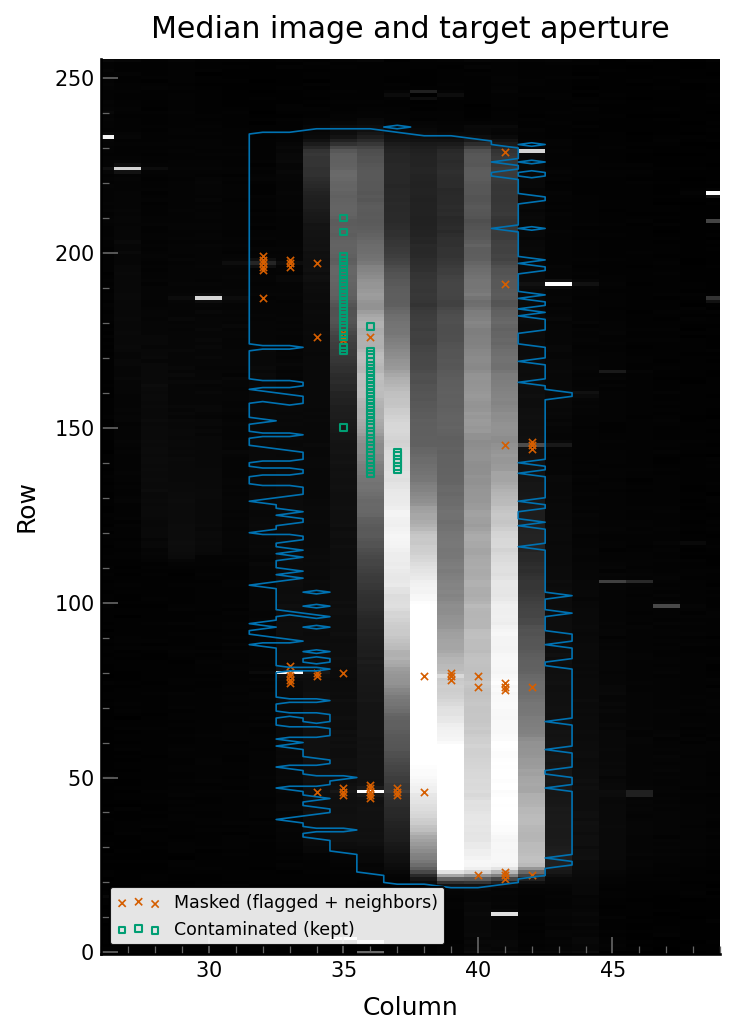

In [7]:
median_image = np.median(cube_clean, axis=0)
fig, ax = plt.subplots(figsize=(5, 7))
image_limits = np.nanpercentile(median_image, [1, 99.5])
ax.imshow(
    median_image, cmap="Greys_r", vmin=image_limits[0],
    vmax=image_limits[1], aspect="auto", interpolation="nearest",
)
ax.contour(target, levels=[0.5], colors="#0072B2", linewidths=0.8)
rows_masked, cols_masked = np.where(masked)
rows_contam, cols_contam = np.where(contaminated)
ax.scatter(cols_masked, rows_masked, s=12, marker="x", color="#D55E00",
           label="Masked (flagged + neighbors)")
ax.scatter(cols_contam, rows_contam, s=10, marker="s", facecolors="none",
           edgecolors="#009E73", label="Contaminated (kept)")
ax.set(title="Median image and target aperture", xlabel="Column",
       ylabel="Row",
       xlim=np.where(target.any(axis=0))[0][[0, -1]] + [-6, 6])
ax.legend(loc="lower left", fontsize="small")
plt.show()

## Spectral time series

Each wavelength is divided by its median over the file, so the image shows relative changes (pointing systematics, the post-slew ramp, a transit if one occurs).

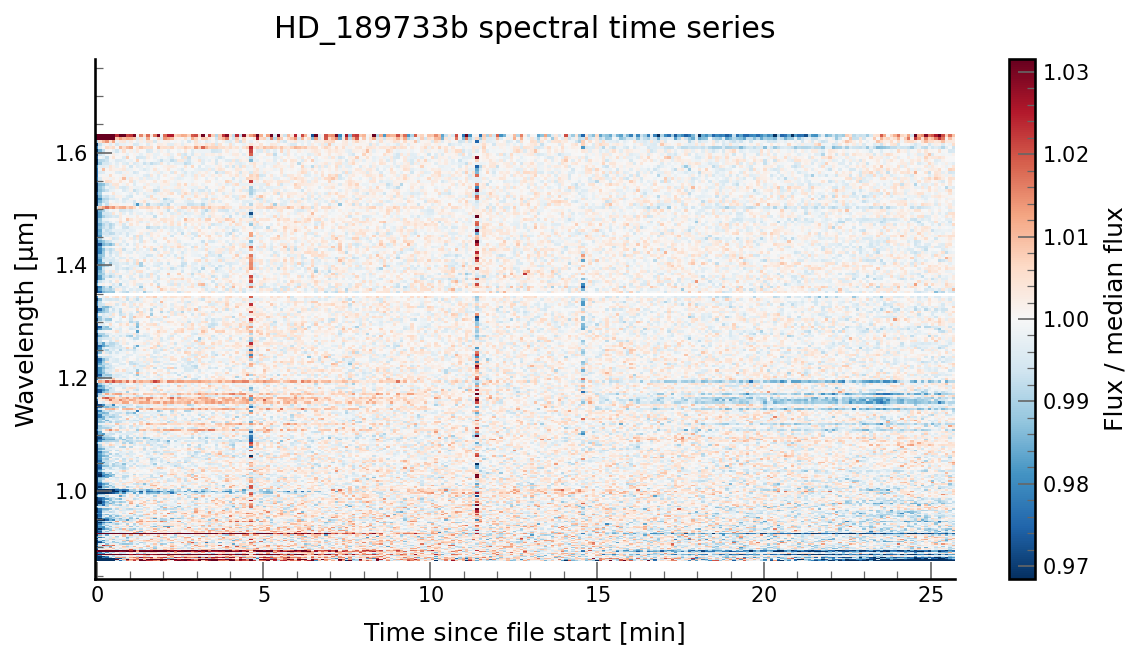

In [8]:
order = np.argsort(wavelength)
relative = spectra / np.nanmedian(spectra, axis=0)
fig, ax = plt.subplots(figsize=(8, 4.5))
limit = np.nanpercentile(np.abs(relative[:, use_row] - 1), 99)
mesh = ax.pcolormesh(
    time_minutes, wavelength[order],
    np.where(use_row, relative, np.nan)[:, order].T,
    cmap="RdBu_r", norm=TwoSlopeNorm(1, 1 - limit, 1 + limit),
    shading="nearest",
)
fig.colorbar(mesh, ax=ax, label="Flux / median flux")
ax.set(xlabel="Time since file start [min]", ylabel="Wavelength [µm]",
       title=f"{header['TARG_ID']} spectral time series")
plt.show()

## Median spectrum

The median over the file of the extracted spectrum, in detector units and flux-calibrated with the sensitivity curve. Rows that were filled and rows that are contaminated (both dropped by the simple recipe) are marked.

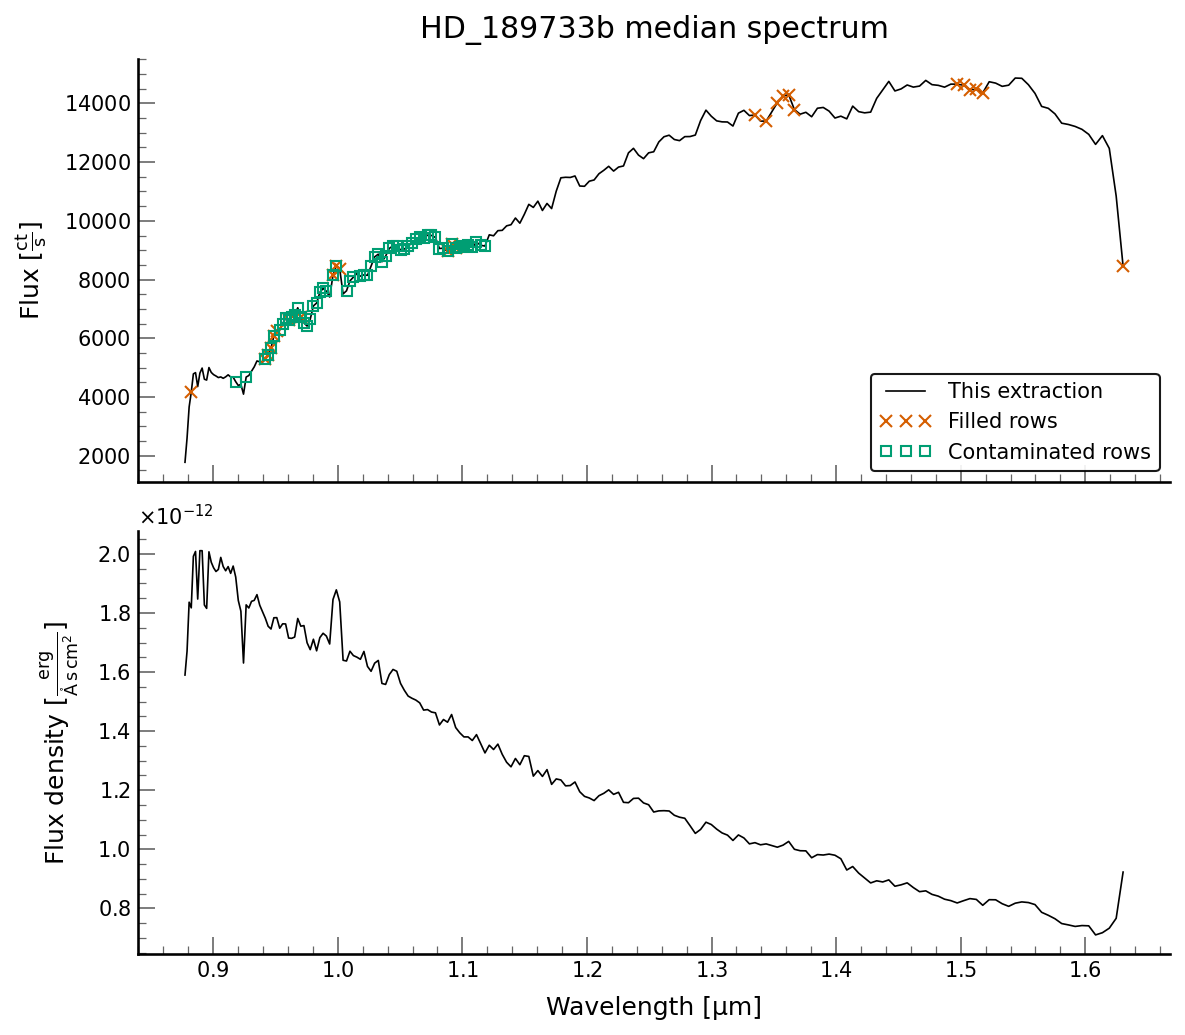

In [9]:
median_spectrum = np.nanmedian(spectra, axis=0)
calibrated_unit = unit / u.Unit(wavelength_table.columns["sensitivity"].unit)
filled_rows = use_row & masked.any(axis=1)
kept_contaminated = use_row & contaminated_rows

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
axes[0].plot(wavelength[use_row], median_spectrum[use_row], color="k",
             label="This extraction")
axes[0].plot(wavelength[filled_rows], median_spectrum[filled_rows], "x",
             color="#D55E00", markersize=6, label="Filled rows")
axes[0].plot(wavelength[kept_contaminated],
             median_spectrum[kept_contaminated], "s", color="#009E73",
             markerfacecolor="none", markersize=5,
             label="Contaminated rows")
axes[0].set(ylabel=f"Flux [{unit.to_string('latex')}]",
            title=f"{header['TARG_ID']} median spectrum")
axes[0].legend(loc="lower right")

axes[1].plot(wavelength[use_row],
             (median_spectrum / sensitivity)[use_row], color="k")
axes[1].set(xlabel="Wavelength [µm]",
            ylabel=f"Flux density [{calibrated_unit.to_string('latex')}]")
plt.show()

## White light curve

The sum over the extracted wavelengths that are not contaminated, normalized to its median.

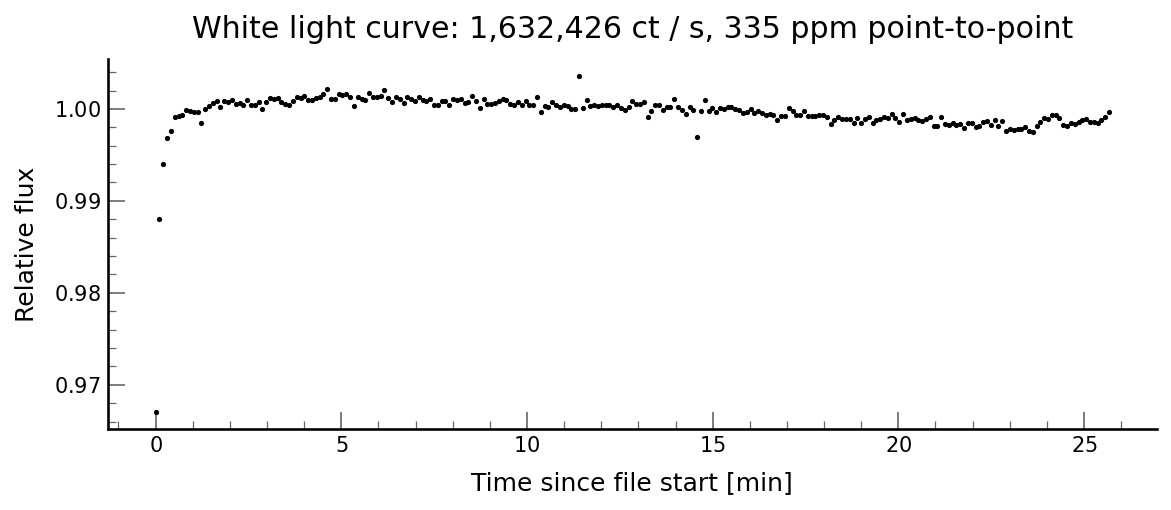

In [10]:
white_rows = use_row & ~contaminated_rows
white = np.nansum(spectra[:, white_rows], axis=1)
white_relative = white / np.median(white)
point_to_point = (
    1.4826 * np.median(np.abs(np.diff(white_relative))) / np.sqrt(2)
)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(time_minutes, white_relative, ".", color="k", markersize=3)
ax.set(xlabel="Time since file start [min]", ylabel="Relative flux",
       title=(f"White light curve: {np.median(white):,.0f} {unit}, "
              f"{point_to_point * 1e6:.0f} ppm point-to-point"))
plt.show()

## Precision per wavelength

The measured point-to-point scatter of each wavelength is compared with the scatter expected from photon noise of the star and the background and from read noise. NIRDA Level 2 frames are the difference of two group averages of `READS` reads each, so each pixel carries a read-noise variance of $2\sigma_\mathrm{read}^2/N_\mathrm{reads}$. A ratio near 1 means the extraction is noise-limited at that wavelength; larger values point to systematics such as pointing jitter.

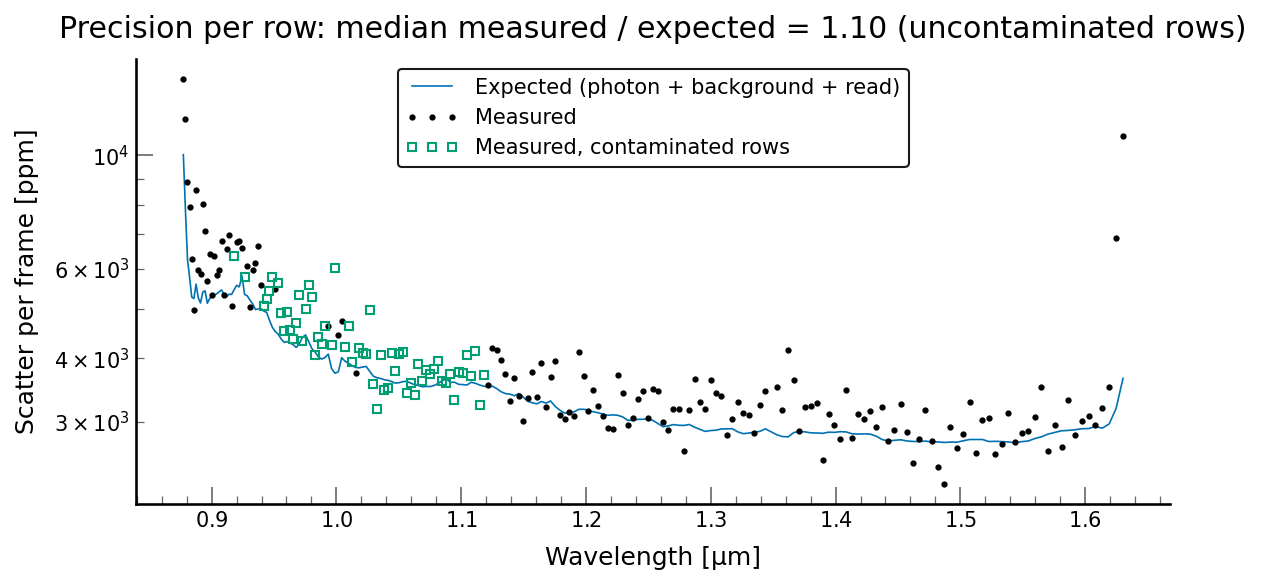

In [11]:
reference = hdulist.reference
gain = reference.get_gain().to(u.electron / u.DN).value
read_noise = reference.get_readnoise(1).value  # DN per read
nreads = header["READS"]

npix_row = target.sum(axis=1)
background_row = np.median(background, axis=0)
variance_rate = (
    (median_spectrum + npix_row * background_row) / (gain * exptime[0])
    + npix_row * 2 * read_noise**2 / nreads / exptime[0] ** 2
)
expected_ppm = 1e6 * np.sqrt(variance_rate) / median_spectrum
measured_ppm = 1e6 * (
    1.4826 * np.nanmedian(np.abs(np.diff(relative, axis=0)), axis=0)
    / np.sqrt(2)
)
ratio = np.nanmedian(measured_ppm[white_rows] / expected_ppm[white_rows])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(wavelength[use_row], expected_ppm[use_row], color="#0072B2",
        label="Expected (photon + background + read)")
ax.plot(wavelength[white_rows], measured_ppm[white_rows], ".", color="k",
        markersize=4, label="Measured")
ax.plot(wavelength[kept_contaminated], measured_ppm[kept_contaminated], "s",
        color="#009E73", markerfacecolor="none", markersize=4,
        label="Measured, contaminated rows")
ax.set(xlabel="Wavelength [µm]", ylabel="Scatter per frame [ppm]",
       yscale="log",
       title=(f"Precision per row: median measured / expected = "
              f"{ratio:.2f} (uncontaminated rows)"))
ax.legend()
plt.show()

## Caveats

These come from the Level 2 products, not from this extraction:

- **`BACKGROUND`** is a per-row median of the non-aperture pixels. In pandora-fits 0.9.0 and earlier it includes the bright first and last columns of the subarray, which makes it slightly too high (a few tenths of a ct/s per pixel). For bright targets this is negligible; for faint ones it lowers the flux by up to a few percent with a wavelength dependence.
- **`TIME`** is, in pandora-fits 0.9.0 and earlier, the start of the second read group, about 1.9 s after the middle of the exposure.
- **Contamination flags** (APERTURE bit 4) come from a scene model that, in pandora-fits 0.9.0 and earlier, scales the stars by their Gaia BP (visible) fluxes. Red neighbors are underflagged in the NIR, so uncontaminated rows may still carry some light from other stars.
- No dark, flat-field or nonlinearity correction is applied at Level 2, so the flux-calibrated spectrum is approximate. Relative quantities (light curves, transit depths) are much less affected.